In [5]:
import sys, os
sys.path.append(os.pardir)
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import os
import math
import time
import torch.optim as optim
from scipy.signal import find_peaks
from matplotlib.ticker import MultipleLocator
from torch.optim.lr_scheduler import LambdaLR
from torch.nn import init
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import Dataset,DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import datetime  #获取日期和时间
%matplotlib inline

In [6]:
# 展示高清图
from matplotlib_inline import backend_inline
backend_inline.set_matplotlib_formats('svg')

In [7]:
os.environ['KMP_DUPLICATE_LIB_OK']='True'
torch.set_float32_matmul_precision('high')

In [8]:
# 制作数据集
class MyData(Dataset):                  # 继承Dataset类
    def __init__(self, filepath):
        ts = filepath   # 导入数据
        self.X = ts[:, :404]                   # 前16列为输入特征
        self.Y = ts[:,-631:]                   # 后611列为输出特征
        self.len = ts.shape[0]                 # 样本的总数
        
    def __getitem__(self, index):
        return self.X[index], self.Y[index]
 
    def __len__(self):
        return self.len

In [9]:
def add_gaussian_noise(signal, noise_level=0.01):
    """
    向信号添加高斯噪声。
    
    参数:
    signal -- numpy数组，原始电流数据。
    noise_level -- 浮点数，表示噪声水平（百分比）。
    
    返回:
    noisy_signal -- 添加了高斯噪声的信号。
    """
    noise = np.random.normal(0, noise_level * np.max(abs(signal)), signal.shape)
    noisy_signal = signal + noise
    return noisy_signal

In [10]:
def add_noise(s, prob=0.5):
    # s: numpy array shape (L,)
    x = s.copy()
    # 加性高斯
    if np.random.rand() < prob:
        sigma = np.random.uniform(0, 0.1*np.max(abs(s)))
        noise = np.random.normal(0, sigma, x.shape)
        x = x + noise
    return x

In [11]:
def normalize_per_device(data, device_num=4, points_per_device=101):
    """
    对每个器件的数据独立进行标准化。

    参数:
        data: 输入数据，形状为 (n, 404)
        device_num: 器件数量，默认 4
        points_per_device: 每个器件的数据点数，默认 101

    返回:
        标准化后的数据，形状与输入一致
    """
    data = np.asarray(data)
    normalized_data = np.zeros_like(data, dtype=np.float64)

    for i in range(device_num):
        start = i * points_per_device
        end = start + points_per_device

        normalized_data[:, start:end] = scaler.fit_transform(data[:, start:end].T).T

    return normalized_data

In [12]:
def generate_baseline(length, prob=0.5):
    if np.random.rand() < prob:
        # 简单的线性或二次基线
        a = np.random.uniform(-0.0003, 0.0003)
        b = np.random.uniform(-0.05, 0.05)
        c = np.random.uniform(0.01, 0.05)
        x_norm = np.linspace(0, 1, length)
        baseline = a * x_norm ** 2 + b * x_norm + c

    else:
        # 中等复杂度基线 - 使用正弦和多项式组合
        coeffs = np.random.normal(0, 0.05, 4)
        x_norm = np.linspace(0, 1, length)

        polynomial = coeffs[0] + coeffs[1] * x_norm + coeffs[2] * x_norm ** 2 + coeffs[3] * x_norm ** 3

        sine_amp = np.random.uniform(0.01, 0.05)
        sine_freq = np.random.uniform(1, 3)
        sine_phase = np.random.uniform(0, 2 * np.pi)
        sine = sine_amp * np.sin(sine_freq * np.pi * x_norm + sine_phase)

        baseline = polynomial + sine + np.random.uniform(0.01, 0.05)
    return np.maximum(baseline, 0.005)

In [13]:
def generate_gaussian_spectrum():
    # 设置波长范围和步长
    wavelengths = np.arange(470, 1100.1, 1)

    # 随机决定峰数量（1、2 或 3），概率分别为 0.2、0.6、0.2
    num_peaks = np.random.choice([1, 2, 3], p=[1.0, 0.0, 0.0])

    # 初始化光谱为全零
    spectrum = np.zeros_like(wavelengths, dtype=float)

    for _ in range(num_peaks):
        # 峰位位置在波长范围内随机选择
        center = np.random.choice(np.arange(470, 1100.1, 1))
        # 半高宽随机选取
        fwhm = np.random.uniform(2.0, 4.0)
        # 根据 FWHM 计算标准差 sigma（FWHM ≈ 2.355 * sigma）
        sigma = fwhm / 2.355
        # 峰值强度随机选取
        amplitude = np.random.uniform(0.5, 1.5)

        # 计算高斯峰
        peak = amplitude * np.exp(-((wavelengths-center)**2)/(2*sigma**2))
#         peak = amplitude * (fwhm/2)**2 / ((wavelengths-center)**2 + (fwhm/2)**2)
        spectrum += peak
        
#     baseline = generate_baseline(331)
#     spectrum += baseline
    return spectrum

In [14]:
def generate_dataset(n):
    Wavelength_jieguo = np.arange(470, 1100.1, 1)
    P_jie = np.zeros((n, 631))
    for i in range(n):
        p = generate_gaussian_spectrum()
        p = p.reshape((1, -1))
        P_jie[i, :] = p
    P_jie = scaler0.fit_transform(P_jie.T).T  
    P_ji = P_jie[:, np.arange(0, P_jie.shape[1], 5)]
    #计算光电流
    I = np.dot(P_ji, R)
    #加噪声
    I_noise1 = np.zeros((n, 404))
    for i in range(n):
        I_noise1[i, : ] = add_noise(I[i, : ])
#     I_noise1 = scaler.fit_transform(I_noise1.T).T       #归一化
    I_noise1 = normalize_per_device(I_noise1)
    I = torch.tensor(I_noise1, dtype=torch.float32).to('cuda:0')
    P = torch.tensor(P_jie, dtype=torch.float32).to('cuda:0')
    return I, P

In [15]:
# 导入响应函数R
file_path = r"C:\6.17\前四号器件\470-1100\所有编码点\响应矩阵(减暗电流).xlsx"
arr = pd.read_excel(file_path, index_col=0).T
R = arr.values
scaler0 = MinMaxScaler()
scaler = StandardScaler()
n_train = 102400
n_val = 25600
I, P = generate_dataset(n_train)
train_Data = MyData(torch.cat([I,P],axis=1))
I, P = generate_dataset(n_val)
val_Data = MyData(torch.cat([I,P],axis=1))

In [16]:
# 批次加载器
train_loader = DataLoader(dataset=train_Data, shuffle=True, batch_size=256)
val_loader = DataLoader(dataset=val_Data, shuffle=True, batch_size=256)

In [17]:
class DNN(nn.Module):
    
    def __init__(self):
        super(DNN, self).__init__()

        self.rec_fc = nn.Sequential(
            nn.Linear(404, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.25),

            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.25),

            nn.Linear(512, 631),
            nn.Sigmoid()
        )

        self.conv = nn.Sequential(
            nn.Conv1d(1, 8, kernel_size=25, padding=12),
            nn.BatchNorm1d(8),
            nn.MaxPool1d(kernel_size=3, stride=2),
            nn.ReLU(),
            
            nn.Conv1d(8, 16, kernel_size=15, stride=2, padding=7),
            nn.BatchNorm1d(16),
            nn.MaxPool1d(kernel_size=3, stride=2),
            nn.ReLU(),
            
            nn.Conv1d(16, 32, kernel_size=11, padding=5),
            nn.BatchNorm1d(32),
            nn.MaxPool1d(kernel_size=3, stride=2),
            nn.ReLU(),
            
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.MaxPool1d(kernel_size=3, stride=2),
            nn.ReLU(),

            nn.Flatten(),
        )

        self.fc = nn.Sequential(
            
            nn.Linear(1152, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(p=0.25),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.25),

            nn.Linear(512, 631),
        )
        

    def forward(self, x: torch.FloatTensor) -> torch.FloatTensor:
        xt = self.rec_fc(x)
        Fx = self.fc(self.conv(xt[:,None,:]))
        out = torch.sigmoid(Fx + xt)
#         out = Fx + xt
        # out = self.output_layer(Fx + xt)
#         out = (Fx + xt) * torch.sigmoid(Fx + xt)

        return out

In [18]:
# 定义模型
# model = DeepDNN().to('cuda:0')
model = DNN().to('cuda:0')
# model = torch.compile(model)

In [19]:
# ====================== 峰位感知损失函数 ======================
class PeakAwareSpectralLoss(nn.Module):
    def __init__(self, stage=0):
        super().__init__()
        self.stage = stage
        
        # 可学习的 log(sigma^2)，初始为 log(1.0)
        self.log_sigma_mse = nn.Parameter(torch.tensor(0.0))
        self.log_sigma_peak = nn.Parameter(torch.tensor(0.0))
        self.log_sigma_deriv = nn.Parameter(torch.tensor(0.0))
    def set_stage(self, stage):
        """设置训练阶段"""
        self.stage = stage
    def forward(self, y_pred, y_true):
        # Stage 0: 初步训练
            # 基础MSE
        if self.stage == 0:
            return F.mse_loss(y_pred, y_true)
        else:
            mse = F.mse_loss(y_pred, y_true)
            peak_loss = self._peak_precision_loss(y_pred, y_true)
            deriv_loss = self._derivative_matching(y_pred, y_true)
#             loss = (
#                 self._uncertainty_weighted_loss(mse, self.log_sigma_mse) +
#                 self._uncertainty_weighted_loss(peak_loss, self.log_sigma_peak) +
#                 self._uncertainty_weighted_loss(deriv_loss, self.log_sigma_deriv)
#             )
            loss = 0.4*mse + 0.3*peak_loss*1.43 + 0.3*deriv_loss*3.06
            return loss

    def _uncertainty_weighted_loss(self, loss_item, log_sigma2):
        return torch.exp(-log_sigma2) * loss_item + log_sigma2
    
    def _peak_precision_loss(self, y_pred, y_true, threshold=0.2, sharpness=100.0):
        y_true_max = torch.amax(y_true, dim=1, keepdim=True)
        score = y_true - (threshold * y_true_max)
        peak_weight = torch.sigmoid(sharpness * score)  # soft mask ∈ (0, 1)

        error = torch.square(y_pred - y_true)
        weighted_error = peak_weight * error
        return torch.mean(weighted_error)

    def _derivative_matching(self, y_pred, y_true):
        # 一阶导数
        true_grad1 = y_true[:, 1:] - y_true[:, :-1]
        pred_grad1 = y_pred[:, 1:] - y_pred[:, :-1]

        # 导数差异
        grad_loss = torch.mean(torch.square(true_grad1 - pred_grad1))

        return grad_loss

In [20]:
class CustomSchedulerWithStageSwitch:
    def __init__(self, optimizer, loss_fn, 
                 init_lr=0.001, min_lr=1e-8, 
                 factor=0.6, patience_lr=5, patience_stage=20):
        """
        自定义学习率调度器（带损失阶段切换）

        参数：
            optimizer: torch.optim 优化器
            loss_fn: PeakAwareSpectralLoss 实例
            init_lr: 初始学习率（默认 0.001）
            min_lr: 最小学习率
            factor: 学习率乘因子（默认 0.6）
            patience_lr: 学习率调整耐心值（默认 5）
            patience_stage: 阶段切换耐心值（默认 20）
        """
        self.optimizer = optimizer
        self.loss_fn = loss_fn
        self.best_val_loss = float('inf')
        self.wait_lr = 0
        self.wait_stage = 0
        self.factor = factor
        self.min_lr = min_lr
        self.patience_lr = patience_lr
        self.patience_stage = patience_stage
        self.stage_switched = False

        # 设置初始学习率
        for param_group in optimizer.param_groups:
            param_group['lr'] = init_lr

    def step(self, val_loss):
        """在每个 epoch 结束后调用"""
        if val_loss < self.best_val_loss - 1e-6:
            # 验证集损失改善
            self.best_val_loss = val_loss
            self.wait_lr = 0
            self.wait_stage = 0
        else:
            # 无改善
            self.wait_lr += 1
            self.wait_stage += 1

        # --- 学习率调整 ---
        if self.wait_lr >= self.patience_lr:
            self._reduce_lr()
            self.wait_lr = 0

        # --- 阶段切换 ---
        if (not self.stage_switched) and (self.wait_stage >= self.patience_stage):
            self._switch_stage()

    def _reduce_lr(self):
        for param_group in self.optimizer.param_groups:
            old_lr = param_group['lr']
            new_lr = max(old_lr * self.factor, self.min_lr)
            param_group['lr'] = new_lr
        print(f"学习率调整为 {new_lr:.6f}")

    def _switch_stage(self):
        self.loss_fn.set_stage(1)
        self.stage_switched = True
        self.wait_stage = 0
        for param_group in self.optimizer.param_groups:
            param_group['lr'] = 0.0001
        print("损失函数切换为 Stage 1，学习率重置为 0.0001")

In [21]:
now = datetime.datetime.now()
formatted_time = now.strftime("%m-%d_%H-%M")#在这里记录好此次训练的起始时间，之后用这个时间值来保存最优模型，即模型中途更新了很多次，
#每次都用这个名称重新写入新的值，不过最优参数一直在改，最后结束时输出的最后一次是这个的，也是最优值，这样一次执行，就会出一个最优结果

In [22]:
folder_path = 'saved_files'
# 如果文件夹不存在，则创建它
if not os.path.exists(folder_path): #os.path.exists函数用于检查指定的文件或目录是否存在。
    os.makedirs(folder_path) #创建文件夹

In [23]:
# 损失函数的选择
criterion = nn.MSELoss()
# 优化算法的选择
learning_rate = 0.001    # 设置学习率
epochs = 300
# optimizer = torch.optim.Adam(list(model.parameters()) + list(criterion.parameters()),lr=learning_rate)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# scheduler = CustomSchedulerWithStageSwitch(optimizer, criterion)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',        # 'min' 表示监控的指标越小越好（如 loss）
    factor=0.6,        # 学习率 *= factor
    patience=5,        # 连续多少个 epoch 没有改善后触发
    min_lr=1e-8,       # 学习率下限
    cooldown=1,        # 降低 lr 后等待多少个 epoch 再监控（避免频繁触发）
)

In [24]:
train_losses = []
val_losses = []
lres = []
early_stop_patience = 25  # 连续10个Epoch不下降就停止
no_improve_epochs = 0     # 计数器
best_loss = float('inf')

for epoch in range(epochs):
    train_loss = val_loss = 0.0
    total_train_samples = total_val_samples = 0
    model.train()
    for X_batch, Y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, Y_batch)
        loss.backward() 
        optimizer.step() 
        batch_size = X_batch.size(0)
        total_train_samples += batch_size
        train_loss += loss.item() * batch_size
    model.eval()
    with torch.no_grad():
        for X_batch, Y_batch in val_loader:
            outputs = model(X_batch)
            batch_size = X_batch.size(0)
            total_val_samples += batch_size
            val_loss += criterion(outputs, Y_batch).item() * batch_size
    train_loss /= total_train_samples
    train_losses.append(train_loss)
    val_loss /= total_val_samples
    val_losses.append(val_loss)
    lres.append(optimizer.param_groups[0]['lr'])
    scheduler.step(val_loss)
    # 保存最优模型
    if val_loss < best_loss:
        print('新训练模型损失值更小，需要进行更新')
        no_improve_epochs = 0  # 重置计数器
        best_loss = val_loss
        file_name = f"best_model233333--Temporary_{formatted_time}.pth"
        torch.save(model.state_dict(), 'best_model233333.pth')
        file_path = os.path.join(folder_path, file_name)
        torch.save(model.state_dict(), file_path)
        print('更新了最佳参数模型！')
    else:
        no_improve_epochs += 1
        print(f"验证集损失未改善计数: {no_improve_epochs}/{early_stop_patience}")
    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, val_loss: {val_loss:.4f}, LR: {optimizer.param_groups[0]['lr']:.2e}")
    if no_improve_epochs >= early_stop_patience:
        print("触发早停，停止训练！")
        break

Fig = plt.figure(figsize=(12, 4))
plt.plot(range(len(train_losses)), train_losses, label="train_loss")
plt.plot(range(len(train_losses)), val_losses, label="val_loss")
plt.legend()
plt.show()

新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 1/300, Train Loss: 0.0080, val_loss: 0.0035, LR: 1.00e-03
新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 2/300, Train Loss: 0.0035, val_loss: 0.0035, LR: 1.00e-03
新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 3/300, Train Loss: 0.0035, val_loss: 0.0035, LR: 1.00e-03
新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 4/300, Train Loss: 0.0035, val_loss: 0.0034, LR: 1.00e-03
新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 5/300, Train Loss: 0.0034, val_loss: 0.0033, LR: 1.00e-03
新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 6/300, Train Loss: 0.0033, val_loss: 0.0032, LR: 1.00e-03
新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 7/300, Train Loss: 0.0032, val_loss: 0.0031, LR: 1.00e-03
验证集损失未改善计数: 1/25
Epoch 8/300, Train Loss: 0.0031, val_loss: 0.0032, LR: 1.00e-03
新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 9/300, Train Loss: 0.0031, val_loss: 0.0030, LR: 1.00e-03
新训练模型损失值更小，需要进行更新
更新了最佳参数模型！
Epoch 10/300, Train Loss: 0.0031, val_loss: 0.0029, LR: 1.00e-03
验证集损失未改善计数: 1/25
Epoch 11/300, Train Loss: 0.0030, val_loss: 0.0033, LR: 1.00e-03

KeyboardInterrupt: 

In [27]:
model.load_state_dict(torch.load('best_model233333--Temporary_06-24_16-24.pth'))
model.eval()  # 设置为评估模式

DNN(
  (rec_fc): Sequential(
    (0): Linear(in_features=404, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=512, out_features=631, bias=True)
    (9): Sigmoid()
  )
  (conv): Sequential(
    (0): Conv1d(1, 8, kernel_size=(25,), stride=(1,), padding=(12,))
    (1): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): MaxPool1d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ReLU()
    (4): Conv1d(8, 16, kernel_size=(15,), stride=(2,), padding=(7,))
    (5): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): MaxPool1d(kernel_size=3,

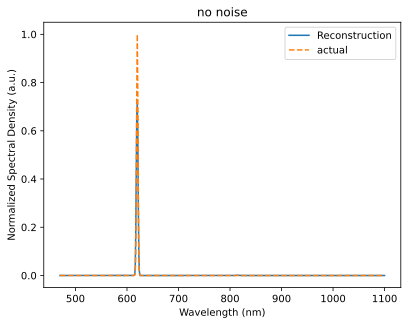

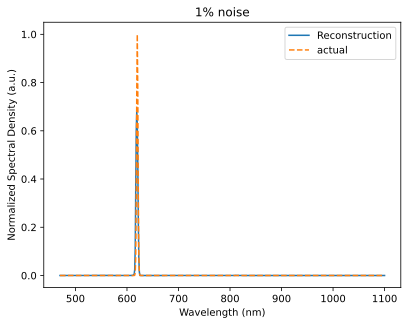

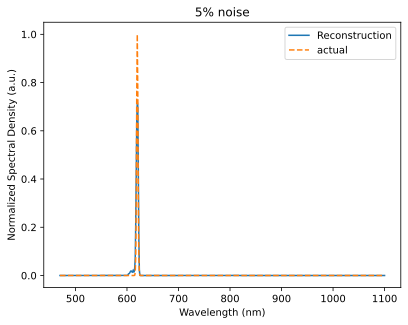

In [28]:
Wavelength_jieguo = np.arange(470, 1100.1, 1)
with torch.no_grad():
    P_actual_jie = generate_gaussian_spectrum()
    P_actual_jie = P_actual_jie.reshape((1, -1))
    P_actual_jie = scaler0.fit_transform(P_actual_jie.T).T
    P_actual_ji = P_actual_jie[:, np.arange(0, P_actual_jie.shape[1], 5)]
    
    I_actual = np.dot(P_actual_ji, R).reshape((-1, 1))
    I_actual = scaler.fit_transform(I_actual)
    I_actua2 = torch.tensor(add_gaussian_noise(I_actual).T, dtype=torch.float32).to('cuda:0')
    I_actua3 = torch.tensor(add_gaussian_noise(I_actual,noise_level=0.05).T, dtype=torch.float32).to('cuda:0')
    I_actual = torch.tensor(I_actual.T, dtype=torch.float32).to('cuda:0')
    model.eval()
    P_Reconstruction1 = model(I_actual).to('cpu').reshape(-1)
    P_Reconstruction2 = model(I_actua2).to('cpu').reshape(-1)
    P_Reconstruction3 = model(I_actua3).to('cpu').reshape(-1)
    Fig1 = plt.figure()
    plt.plot(Wavelength_jieguo, P_Reconstruction1, label="Reconstruction")
    plt.plot(Wavelength_jieguo, P_actual_jie.reshape(-1), linestyle="--", label="actual")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Normalized Spectral Density (a.u.)")
    plt.title('no noise')
    plt.legend()
    plt.show()
    Fig2 = plt.figure()
    plt.plot(Wavelength_jieguo, P_Reconstruction2, label="Reconstruction")
    plt.plot(Wavelength_jieguo, P_actual_jie.reshape(-1), linestyle="--", label="actual")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Normalized Spectral Density (a.u.)")
    plt.title('1% noise')
    plt.legend()
    plt.show()
    Fig3 = plt.figure()
    plt.plot(Wavelength_jieguo, P_Reconstruction3, label="Reconstruction")
    plt.plot(Wavelength_jieguo, P_actual_jie.reshape(-1), linestyle="--", label="actual")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Normalized Spectral Density (a.u.)")
    plt.title('5% noise')
    plt.legend()
    plt.show()

In [23]:
P_actual_jie.shape

(1, 631)

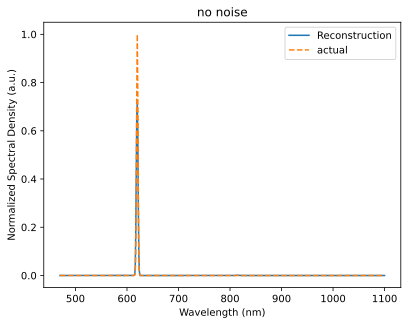

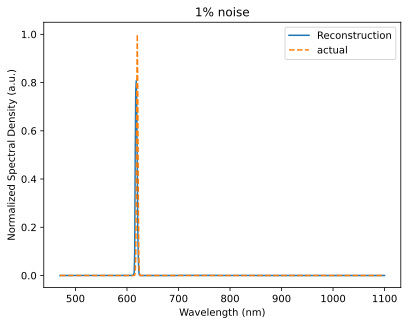

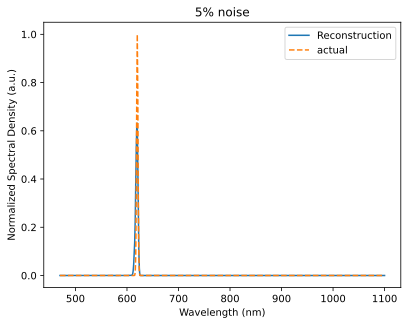

In [29]:
with torch.no_grad():
    I_actual = np.dot(P_actual_ji, R)
    I_actua2 = add_gaussian_noise(I_actual)
    I_actua3 = add_gaussian_noise(I_actual,noise_level=0.05)
    I_actua2 = torch.tensor(scaler.fit_transform(I_actua2.reshape((-1, 1))).T, dtype=torch.float32).to('cuda:0')
    I_actua3 = torch.tensor(scaler.fit_transform(I_actua3.reshape((-1, 1))).T, dtype=torch.float32).to('cuda:0')
    I_actual = torch.tensor(scaler.fit_transform(I_actual.reshape((-1, 1))).T, dtype=torch.float32).to('cuda:0')
    P_Reconstruction1 = model(I_actual).to('cpu').reshape(-1)
    P_Reconstruction2 = model(I_actua2).to('cpu').reshape(-1)
    P_Reconstruction3 = model(I_actua3).to('cpu').reshape(-1)
    Fig1 = plt.figure()
    plt.plot(Wavelength_jieguo, P_Reconstruction1, label="Reconstruction")
    plt.plot(Wavelength_jieguo, P_actual_jie.reshape(-1), linestyle="--", label="actual")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Normalized Spectral Density (a.u.)")
    plt.title('no noise')
    plt.legend()
    plt.show()
    Fig2 = plt.figure()
    plt.plot(Wavelength_jieguo, P_Reconstruction2, label="Reconstruction")
    plt.plot(Wavelength_jieguo, P_actual_jie.reshape(-1), linestyle="--", label="actual")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Normalized Spectral Density (a.u.)")
    plt.title('1% noise')
    plt.legend()
    plt.show()
    Fig3 = plt.figure()
    plt.plot(Wavelength_jieguo, P_Reconstruction3, label="Reconstruction")
    plt.plot(Wavelength_jieguo, P_actual_jie.reshape(-1), linestyle="--", label="actual")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Normalized Spectral Density (a.u.)")
    plt.title('5% noise')
    plt.legend()
    plt.show()

In [30]:
def find_max_and_index(vector):
    # 假设向量的第一个元素是最大值，并且它的位置是0
    max_value = vector[0]
    max_index = 0

    # 遍历向量中的所有元素
    for i in range(1, len(vector)):
        # 如果当前元素大于已知的最大值
        if vector[i] > max_value:
            # 更新最大值，并记录该元素的位置
            max_value = vector[i]
            max_index = i

    # 返回最大值和它的位置
    return max_value, max_index

In [35]:
with torch.no_grad():
    # 同步 GPU，确保时间准确
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.time()
    # 模型推理
    file_path = r"C:\6.17\前四号器件\470-1100\所有编码点\验证单峰(减暗电流).xlsx"
    arr = pd.read_excel(file_path, index_col=0, header=None)
    I_yz = arr.values
    I_yz = scaler.fit_transform(I_yz.T).T
#     I_yz = normalize_per_device(I_yz)
    I_yz = torch.tensor(I_yz, dtype=torch.float32).to('cuda:0')
    P_Reconstruction = model(I_yz).to('cpu')
    P_Reconstruction = scaler0.fit_transform(P_Reconstruction.T).T
    # 再次同步 GPU，确保模型执行完毕
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    end = time.time()
print(f"预测耗时：{end - start:.6f} 秒")

预测耗时：0.471030 秒


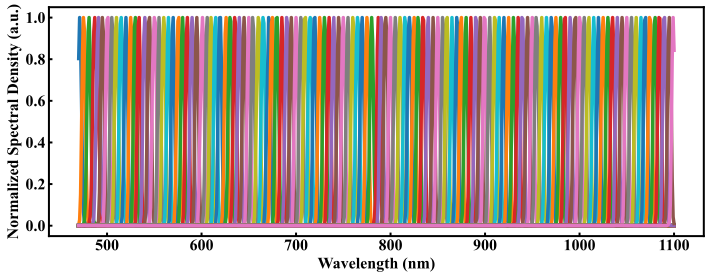

In [36]:
Fig1 = plt.figure(figsize=(10, 4))
ax = plt.gca()  # 获取当前坐标轴对象
for i in range(127):
    ax.plot(Wavelength_jieguo, P_Reconstruction[i, :], linewidth=3.5)
#     ax.plot(Wavelength_jieguo, P_gao[i, :], linewidth=2, ls='--')
# ===== 坐标轴标签 =====
ax.set_xlabel("Wavelength (nm)", fontname='Times New Roman', fontweight='bold', fontsize=16)
ax.set_ylabel("Normalized Spectral Density (a.u.)", fontname='Times New Roman', fontweight='bold', fontsize=16)

# ===== 刻度字体 + 刻度线方向 =====
ax.tick_params(
    direction='in',      # 刻度线朝内
    length=3.5,            # 刻度线长度
    width=2,           # 刻度线粗细
    labelsize=16         # 刻度数字字体大小
)
# 刻度字体设为 Times New Roman + 加粗
for label in (ax.get_xticklabels() + ax.get_yticklabels()):
    label.set_fontname('Times New Roman')
    label.set_fontweight('bold')

# ===== 坐标轴线条加粗 + 显示四边框 =====
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(2)

# ===== 导出数据（可选）=====
df = pd.DataFrame(P_Reconstruction, columns=Wavelength_jieguo)
# df.to_excel('单峰重构(164).xlsx', index=False)
# plt.savefig('单峰重构(164).png', dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()

In [37]:
Wave = np.arange(470, 1100.1, 5)
Wave = torch.from_numpy(Wave).float()
# P_Reconstruction = torch.from_numpy(P_Reconstruction).float()
max_value , Peak = torch.topk(P_Reconstruction, k=1, dim=1)
Peak_Error = Wave - (470 + Peak.reshape(-1))
Peak_pjError = torch.mean(abs(Peak_Error))
print(f"平均峰位误差：{Peak_pjError} ")

TypeError: topk(): argument 'input' (position 1) must be Tensor, not numpy.ndarray

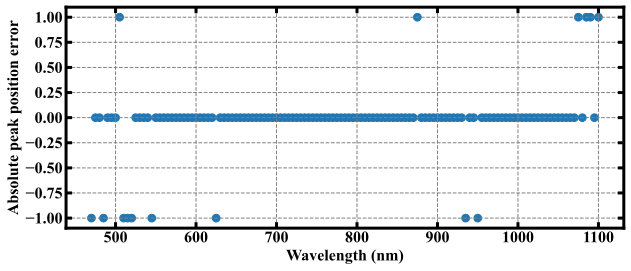

In [30]:
max_value , Peak = torch.topk(P_Reconstruction, k=1, dim=1)
Peak_Error = Wave - (470 + Peak.reshape(-1))
Fig = plt.figure(figsize=(10, 4))
plt.scatter(Wave, Peak_Error, s=60)
# 网格线
plt.grid(True, linestyle='--', linewidth=1, color='gray', alpha=1)
# 字体、字号、加粗
plt.xlabel('Wavelength (nm)', fontname='Times New Roman', fontsize=16, fontweight='bold')
plt.ylabel('Absolute peak position error', fontname='Times New Roman', fontsize=16, fontweight='bold')
# 坐标刻度字体与方向
plt.xticks(fontsize=16, fontname='Times New Roman', fontweight='bold')
plt.yticks(fontsize=16, fontname='Times New Roman', fontweight='bold')
# 坐标轴刻度线设置
plt.tick_params(direction='in', length=6, width=3, top=True, right=True)
# 坐标轴线条加粗并显示四边
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(3)  # 边框加粗
# 保存图像（可选）
# plt.savefig("峰位误差(164).png", dpi=600, bbox_inches='tight')
plt.show()

In [31]:
with torch.no_grad():
    # 同步 GPU，确保时间准确
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.time()
    # 模型推理
    file_path = r"C:\6.17\前四号器件\470-1100\所有编码点\验证单峰(减暗电流).xlsx"
    arr = pd.read_excel(file_path, index_col=0, header=None)
    I_yz = arr.values
    #加噪声
    I_noise = np.zeros((127, 404))
    for i in range(127):
        I_noise[i, : ] = add_gaussian_noise(I_yz[i, : ] ,noise_level=0.05)
    I_noise = scaler.fit_transform(I_noise.T).T       #归一化
    I = torch.tensor(I_noise, dtype=torch.float32).to('cuda:0')
    P_Reconstruction = model(I).to('cpu')
    P_Reconstruction = scaler0.fit_transform(P_Reconstruction.T).T
    # 再次同步 GPU，确保模型执行完毕
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    end = time.time()
print(f"预测耗时：{end - start:.6f} 秒")

预测耗时：0.351208 秒


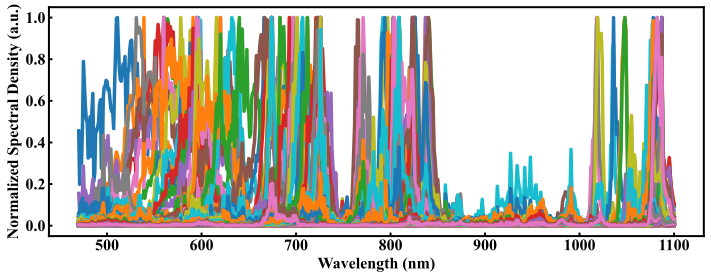

In [32]:
Fig1 = plt.figure(figsize=(10, 4))
ax = plt.gca()  # 获取当前坐标轴对象
for i in range(127):
    ax.plot(Wavelength_jieguo, P_Reconstruction[i, :], linewidth=3.5)
#     ax.plot(Wavelength_jieguo, P_gao[i, :], linewidth=2, ls='--')
# ===== 坐标轴标签 =====
ax.set_xlabel("Wavelength (nm)", fontname='Times New Roman', fontweight='bold', fontsize=16)
ax.set_ylabel("Normalized Spectral Density (a.u.)", fontname='Times New Roman', fontweight='bold', fontsize=16)

# ===== 刻度字体 + 刻度线方向 =====
ax.tick_params(
    direction='in',      # 刻度线朝内
    length=3.5,            # 刻度线长度
    width=2,           # 刻度线粗细
    labelsize=16         # 刻度数字字体大小
)
# 刻度字体设为 Times New Roman + 加粗
for label in (ax.get_xticklabels() + ax.get_yticklabels()):
    label.set_fontname('Times New Roman')
    label.set_fontweight('bold')

# ===== 坐标轴线条加粗 + 显示四边框 =====
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(2)

# ===== 导出数据（可选）=====
df = pd.DataFrame(P_Reconstruction, columns=Wavelength_jieguo)
# df.to_excel('单峰重构(164).xlsx', index=False)
# plt.savefig('单峰重构(164).png', dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()

In [ ]:
Wave = np.arange(470, 1100.1, 5)
Wave = torch.from_numpy(Wave).float()
P_Reconstruction = torch.from_numpy(P_Reconstruction).float()
max_value , Peak = torch.topk(P_Reconstruction, k=1, dim=1)
Peak_Error = Wave - (470 + Peak.reshape(-1))
Peak_pjError = torch.mean(abs(Peak_Error))
print(f"平均峰位误差：{Peak_pjError} ")